Preparando escenarios para el PCA...


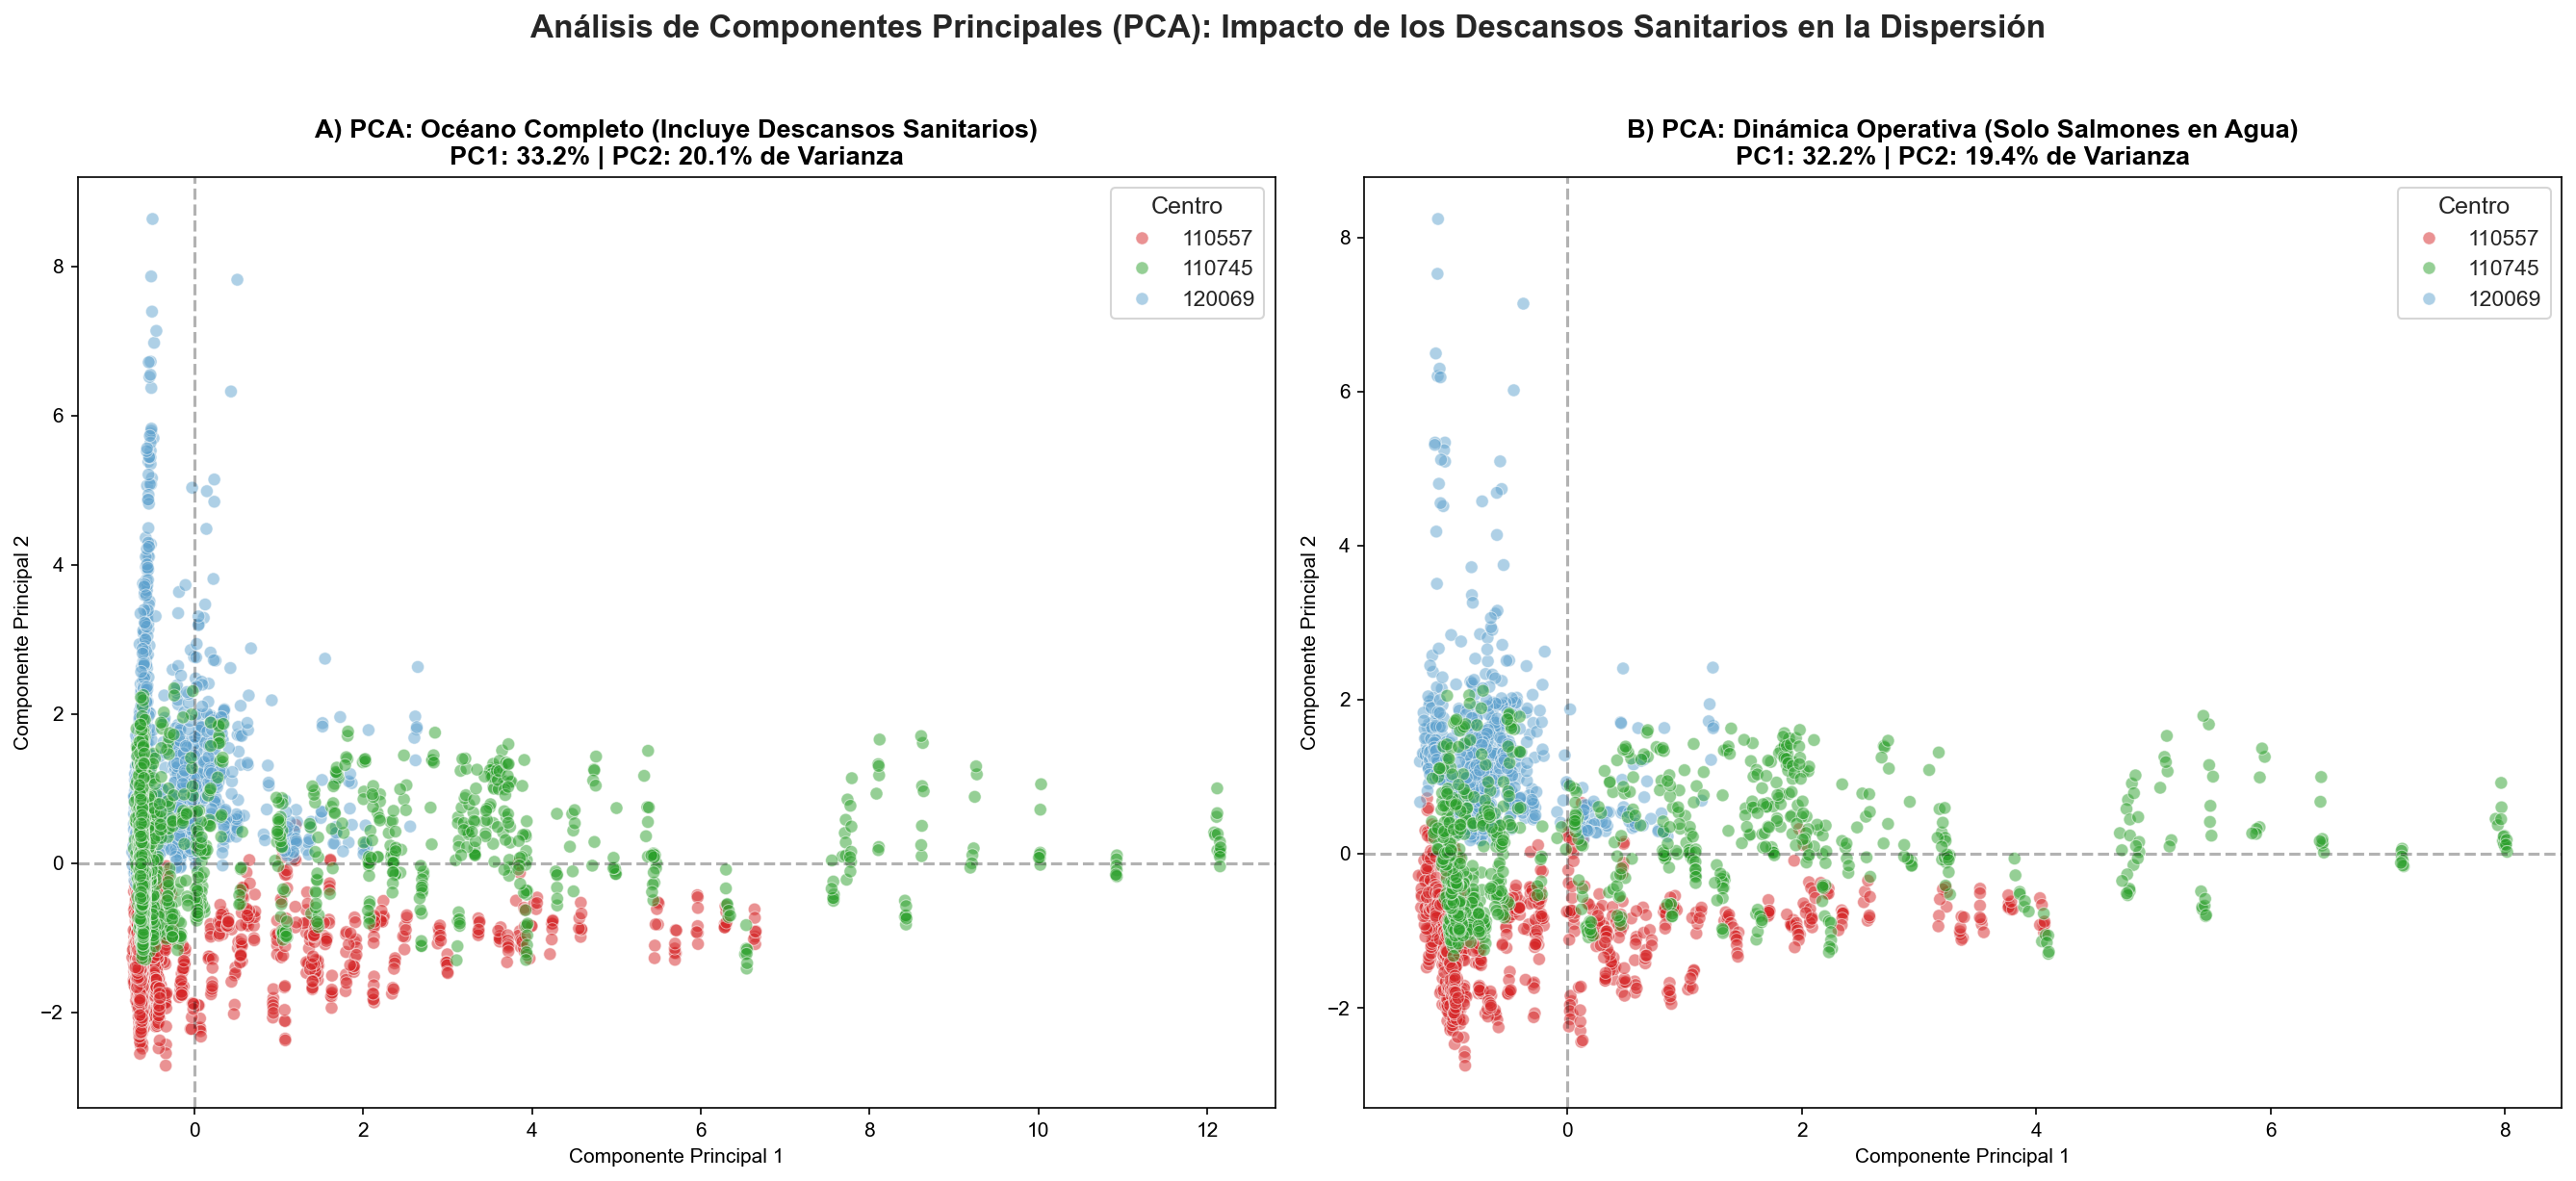


=== Peso de las Variables Originales en el Escenario B (Operativo) ===
Valores cercanos a 1 o -1 tiran con más fuerza del eje.
                           PC1    PC2
Temperatura_C            0.042 -0.562
Salinidad_psu            0.019  0.601
Capa_Mezcla_m            0.002  0.557
Altura_Mar_m            -0.039 -0.043
Velocidad_Corriente_m_s -0.014  0.100
Juveniles                0.570  0.028
Adultos_Moviles          0.578 -0.011
Hembras_Ovigeras         0.581  0.002

Gráfico guardado en: Resultados_Exploracion/PCA/PCA_Comparativo_Centros.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import os

# ==========================================
# 1. Configuración Inicial
# ==========================================
ruta_dataset = "data/Dataset_Maestro_Amplificado_ML.csv"
carpeta_destino = "Resultados_Exploracion/PCA/"
os.makedirs(carpeta_destino, exist_ok=True)

df = pd.read_csv(ruta_dataset)
col_centro = 'id_centro'

variables_fisicas = ['Temperatura_C', 'Salinidad_psu', 'Capa_Mezcla_m', 'Altura_Mar_m', 'Velocidad_Corriente_m_s']
variables_biologicas = ['Juveniles', 'Adultos_Moviles', 'Hembras_Ovigeras']
variables_pca = variables_fisicas + variables_biologicas

paleta_centros = {110557: '#d62728', 120069: '#5fa2ce', 110745: '#2ca02c'}

print("Preparando escenarios para el PCA...")

# ==========================================
# 2. Creación de los Dos Escenarios
# ==========================================
# ESCENARIO A: Todos los datos (Océano ininterrumpido)
df_all = df.copy()
df_all[variables_biologicas] = df_all[variables_biologicas].fillna(0)
df_all = df_all.dropna(subset=variables_fisicas)

# ESCENARIO B: Solo Operativos
df_active = df[df['Nivel_Riesgo_HO'] != 'Desconocido'].copy()
df_active = df_active.dropna(subset=variables_pca)

# ==========================================
# 3. Función para ejecutar PCA
# ==========================================
def aplicar_pca(datos, features):
    # Estandarización obligatoria (media 0, varianza 1)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(datos[features])
    
    # Modelo PCA
    pca = PCA(n_components=2)
    componentes = pca.fit_transform(X_scaled)
    
    # Varianza explicada
    var_exp = pca.explained_variance_ratio_ * 100
    
    # DataFrame con resultados
    df_pca = pd.DataFrame(data=componentes, columns=['PC1', 'PC2'])
    df_pca['id_centro'] = datos['id_centro'].values
    
    # Extraer las cargas (loadings) de las variables originales
    loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=features)
    
    return df_pca, var_exp, loadings

pca_all_df, var_all, loadings_all = aplicar_pca(df_all, variables_pca)
pca_act_df, var_act, loadings_act = aplicar_pca(df_active, variables_pca)

# ==========================================
# 4. Renderizado del Gráfico Comparativo
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(18, 8), dpi=150)
sns.set_theme(style="whitegrid")

# Plot Escenario A
sns.scatterplot(x='PC1', y='PC2', hue='id_centro', palette=paleta_centros, 
                data=pca_all_df, alpha=0.5, s=40, ax=axes[0])
axes[0].set_title(f"A) PCA: Océano Completo (Incluye Descansos Sanitarios)\nPC1: {var_all[0]:.1f}% | PC2: {var_all[1]:.1f}% de Varianza", 
                  fontweight='bold', fontsize=13)
axes[0].set_xlabel(f"Componente Principal 1")
axes[0].set_ylabel(f"Componente Principal 2")

# Plot Escenario B
sns.scatterplot(x='PC1', y='PC2', hue='id_centro', palette=paleta_centros, 
                data=pca_act_df, alpha=0.5, s=40, ax=axes[1])
axes[1].set_title(f"B) PCA: Dinámica Operativa (Solo Salmones en Agua)\nPC1: {var_act[0]:.1f}% | PC2: {var_act[1]:.1f}% de Varianza", 
                  fontweight='bold', fontsize=13)
axes[1].set_xlabel(f"Componente Principal 1")
axes[1].set_ylabel(f"Componente Principal 2")

# Unificar leyendas
for ax in axes:
    ax.legend(title="Centro", loc="best")
    ax.axhline(0, color='black', linestyle='--', alpha=0.3)
    ax.axvline(0, color='black', linestyle='--', alpha=0.3)

plt.suptitle("Análisis de Componentes Principales (PCA): Impacto de los Descansos Sanitarios en la Dispersión", 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

ruta_plot = os.path.join(carpeta_destino, "PCA_Comparativo_Centros.png")
plt.savefig(ruta_plot, bbox_inches='tight')
plt.show()

# ==========================================
# 5. Imprimir las cargas (Loadings) en Consola
# ==========================================
print("\n=== Peso de las Variables Originales en el Escenario B (Operativo) ===")
print("Valores cercanos a 1 o -1 tiran con más fuerza del eje.")
print(loadings_act.round(3).to_string())
print(f"\nGráfico guardado en: {ruta_plot}")

In [ ]:
import pandas as pd
import numpy as np

# Cargar dataset
df = pd.read_csv("data/Dataset_Maestro_Amplificado_ML.csv")


df_biologia_pura = df[df['Nivel_Riesgo_HO'] != 'Desconocido']

variables_bio = ['Juveniles', 'Adultos_Moviles', 'Hembras_Ovigeras', 'Total_Parasitos_']


df_medianas_bio = df_biologia_pura.groupby('id_centro')[variables_bio].median()
df_medianas_bio.index = df_medianas_bio.index.map({110557: "Rojo", 120069: "Azul", 110745: "Verde"})


rojo = df_medianas_bio.loc["Rojo"]
azul = df_medianas_bio.loc["Azul"]
verde = df_medianas_bio.loc["Verde"]

df_deltas_bio = pd.DataFrame({
    'Verde vs Azul (Solo Operativo)': verde - azul,
    'Verde vs Rojo (Solo Operativo)': verde - rojo
}).round(3)

print("--- DELTAS BIOLÓGICOS PUROS (SIN DESCANSOS SANITARIOS) ---")
print(df_deltas_bio.to_string())

--- DELTAS BIOLÓGICOS PUROS (SIN DESCANSOS SANITARIOS) ---
                  Verde vs Azul (Solo Operativo)  Verde vs Rojo (Solo Operativo)
Juveniles                                  0.350                           0.425
Adultos_Moviles                            0.438                           0.558
Hembras_Ovigeras                           0.167                           0.292
Total_Parasitos_                           1.137                           1.575


In [ ]:
"""
PCA — Paso 1: Exploración de componentes
=========================================
Calcula todos los componentes posibles para ambos enfoques:

  Enfoque 1 — Solo variables físicas, dataset completo
  Enfoque 2 — Variables físicas + biológicas, dataset operativo

Outputs en Resultados_PCA/
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import os

# ==========================================
# 1. Configuración
# ==========================================
ruta_dataset = "data/Dataset_Maestro_Amplificado_ML.csv"
carpeta_out  = "Resultados_PCA/"
os.makedirs(carpeta_out, exist_ok=True)

df = pd.read_csv(ruta_dataset)
df['Fecha'] = pd.to_datetime(df['Fecha'])

def asignar_estacion(fecha):
    mes = fecha.month
    if mes in [12, 1, 2]:  return 'Verano'
    elif mes in [3, 4, 5]: return 'Otoño'
    elif mes in [6, 7, 8]: return 'Invierno'
    else:                  return 'Primavera'

df['Estacion'] = df['Fecha'].apply(asignar_estacion)

df['Velocidad_Corriente_m_s'] = np.sqrt(
    df['Corriente_E_m_s']**2 + df['Corriente_N_m_s']**2
)

variables_fisicas    = ['Temperatura_C', 'Salinidad_psu', 'Capa_Mezcla_m',
                        'Altura_Mar_m', 'Velocidad_Corriente_m_s']
variables_biologicas = ['Juveniles', 'Adultos_Moviles', 'Hembras_Ovigeras']

etiquetas = {
    'Temperatura_C'          : 'Temp (°C)',
    'Salinidad_psu'          : 'Salinidad',
    'Capa_Mezcla_m'          : 'Capa Mezcla',
    'Altura_Mar_m'           : 'Altura Mar',
    'Velocidad_Corriente_m_s': 'Vel. Corriente',
    'Juveniles'              : 'Juveniles',
    'Adultos_Moviles'        : 'Adultos Móv.',
    'Hembras_Ovigeras'       : 'Hembras Ov.'
}

paleta_centros = {
    110557: '#d62728',
    120069: '#5fa2ce',
    110745: '#2ca02c'
}

# ==========================================
# 2. Preparación de datasets
# ==========================================
df1 = df.dropna(subset=variables_fisicas).copy()


df2 = df[df['Nivel_Riesgo_HO'] != 'Desconocido'].dropna(
    subset=variables_fisicas + variables_biologicas
).copy()

print("=" * 65)
print("PCA — Paso 1: Exploración de componentes")
print("=" * 65)
print(f"\nEnfoque 1 — Físicas, dataset completo:        n = {len(df1)}")
print(f"Enfoque 2 — Físicas + Biológicas, operativo:  n = {len(df2)}")


# ==========================================
# 3. Función PCA completo
# ==========================================
def ejecutar_pca_completo(datos, variables, nombre_enfoque,
                          prefijo_archivo):

    print(f"\n{'─' * 65}")
    print(f"  {nombre_enfoque}")
    print(f"{'─' * 65}")


    scaler   = StandardScaler()
    X_scaled = scaler.fit_transform(datos[variables])


    n_vars = len(variables)
    pca    = PCA(n_components=n_vars)
    coords = pca.fit_transform(X_scaled)

    var_exp  = pca.explained_variance_ratio_ * 100
    var_acum = np.cumsum(var_exp)
    loadings = pd.DataFrame(
        pca.components_.T,
        columns=[f'PC{i+1}' for i in range(n_vars)],
        index=variables
    )

    print(f"\n  Varianza explicada por componente:")
    print(f"  {'PC':<6} {'Individual (%)':>15} {'Acumulada (%)':>15}")
    print(f"  {'─'*40}")
    for i, (vi, va) in enumerate(zip(var_exp, var_acum)):
        marca = ''
        if abs(va - 70) < vi: marca = '← 70%'
        if abs(va - 80) < vi: marca = '← 80%'
        if abs(va - 90) < vi: marca = '← 90%'
        print(f"  PC{i+1:<4} {vi:>14.2f}% {va:>14.2f}%  {marca}")

    for umbral in [70, 80, 90]:
        n_needed = int(np.searchsorted(var_acum, umbral) + 1)
        print(f"\n  Para explicar >{umbral}% de la varianza: {n_needed} componentes")

    # ── Consola: loadings PC1 y PC2 ──
    print(f"\n  Loadings PC1 y PC2:")
    print(f"  {'Variable':<25} {'PC1':>8} {'PC2':>8}")
    print(f"  {'─'*44}")
    for var in variables:
        l1 = loadings.loc[var, 'PC1']
        l2 = loadings.loc[var, 'PC2']
        bar1 = '█' * int(abs(l1) * 10)
        bar2 = '█' * int(abs(l2) * 10)
        signo1 = '+' if l1 > 0 else '-'
        signo2 = '+' if l2 > 0 else '-'
        label = etiquetas.get(var, var)
        print(f"  {label:<25} {signo1}{abs(l1):.3f} {bar1:<10} "
              f"{signo2}{abs(l2):.3f} {bar2}")

    # ==========================================
    # GRÁFICO A — Scree plot
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=140)
    sns.set_theme(style='whitegrid')

    pcs = [f'PC{i+1}' for i in range(n_vars)]

    # Barras de varianza individual
    axes[0].bar(pcs, var_exp, color='steelblue', alpha=0.75, edgecolor='white')
    axes[0].plot(pcs, var_exp, 'o-', color='navy', linewidth=1.8, markersize=6)
    axes[0].set_xlabel('Componente Principal')
    axes[0].set_ylabel('Varianza explicada (%)')
    axes[0].set_title('Varianza Explicada por Componente')
    axes[0].tick_params(axis='x', rotation=45)

    # Curva acumulada con líneas de referencia
    axes[1].plot(pcs, var_acum, 's-', color='darkorange',
                 linewidth=2, markersize=7)
    for umbral, color in [(70, '#2ca02c'), (80, '#ff7f0e'), (90, '#d62728')]:
        axes[1].axhline(umbral, linestyle='--', linewidth=1.2,
                        color=color, alpha=0.7, label=f'{umbral}%')
    axes[1].set_xlabel('Componente Principal')
    axes[1].set_ylabel('Varianza acumulada (%)')
    axes[1].set_title('Varianza Acumulada')
    axes[1].legend(title='Umbral', fontsize=9)
    axes[1].set_ylim([0, 105])
    axes[1].tick_params(axis='x', rotation=45)

    plt.suptitle(f'Scree Plot — {nombre_enfoque}',
                 fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    ruta_scree = os.path.join(carpeta_out, f'{prefijo_archivo}_scree.png')
    plt.savefig(ruta_scree, bbox_inches='tight')
    plt.close()
    print(f"\n  Scree plot exportado: {ruta_scree}")

    # ==========================================
    # GRÁFICO B — Biplot PC1 vs PC2
    # (scatterplot de observaciones + flechas de loadings)
    # ==========================================
    df_plot = pd.DataFrame({
        'PC1'      : coords[:, 0],
        'PC2'      : coords[:, 1],
        'id_centro': datos['id_centro'].values
    })


    scale = max(abs(coords[:, 0]).max(), abs(coords[:, 1]).max()) * 0.45

    fig, ax = plt.subplots(figsize=(11, 8), dpi=140)
    sns.set_theme(style='whitegrid')

    # Scatterplot por centro
    for centro, color in paleta_centros.items():
        mask = df_plot['id_centro'] == centro
        ax.scatter(
            df_plot.loc[mask, 'PC1'],
            df_plot.loc[mask, 'PC2'],
            color=color, alpha=0.30, s=15,
            edgecolors='none', label=f'Centro {centro}'
        )

    # Flechas de loadings (biplot)
    for var in variables:
        l1 = loadings.loc[var, 'PC1'] * scale
        l2 = loadings.loc[var, 'PC2'] * scale
        ax.annotate(
            '', xy=(l1, l2), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='black',
                            lw=1.8, mutation_scale=15)
        )
        # Offset del texto para que no tape la flecha
        offset_x = l1 * 1.15
        offset_y = l2 * 1.15
        ax.text(offset_x, offset_y, etiquetas.get(var, var),
                fontsize=9, fontweight='bold', color='black',
                ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.2',
                          facecolor='white', alpha=0.6, edgecolor='none'))

    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.axvline(0, color='grey', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', fontsize=11)
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', fontsize=11)
    ax.set_title(
        f'Biplot PC1 vs PC2 — {nombre_enfoque}\n'
        f'Varianza acumulada PC1+PC2: {var_exp[0]+var_exp[1]:.1f}%',
        fontsize=12, fontweight='bold'
    )
    ax.legend(title='Centro', fontsize=9, markerscale=2,
              loc='upper right', framealpha=0.8)

    plt.tight_layout()
    ruta_biplot = os.path.join(carpeta_out, f'{prefijo_archivo}_biplot.png')
    plt.savefig(ruta_biplot, bbox_inches='tight')
    plt.close()
    print(f"  Biplot exportado: {ruta_biplot}")

    return coords, var_exp, var_acum, loadings


# ==========================================
# 4. Ejecución de ambos enfoques
# ==========================================
coords1, var1, vacum1, load1 = ejecutar_pca_completo(
    df1, variables_fisicas,
    nombre_enfoque  = 'Enfoque 1 — Variables Físicas (Dataset Completo)',
    prefijo_archivo = 'E1_fisicas'
)

coords2, var2, vacum2, load2 = ejecutar_pca_completo(
    df2, variables_fisicas + variables_biologicas,
    nombre_enfoque  = 'Enfoque 2 — Variables Físicas + Biológicas (Operativo)',
    prefijo_archivo = 'E2_fisicas_bio'
)


PCA — Paso 1: Exploración de componentes

Enfoque 1 — Físicas, dataset completo:        n = 5844
Enfoque 2 — Físicas + Biológicas, operativo:  n = 2378

─────────────────────────────────────────────────────────────────
  Enfoque 1 — Variables Físicas (Dataset Completo)
─────────────────────────────────────────────────────────────────

  Varianza explicada por componente:
  PC      Individual (%)   Acumulada (%)
  ────────────────────────────────────────
  PC1             32.20%          32.20%  
  PC2             24.15%          56.34%  ← 80%
  PC3             18.43%          74.77%  ← 90%
  PC4             14.12%          88.89%  ← 90%
  PC5             11.11%         100.00%  ← 90%

  Para explicar >70% de la varianza: 3 componentes

  Para explicar >80% de la varianza: 4 componentes

  Para explicar >90% de la varianza: 5 componentes

  Loadings PC1 y PC2:
  Variable                       PC1      PC2
  ────────────────────────────────────────────
  Temp (°C)                 -0.534 

**XXXXX**

In [23]:
"""
Evaluación Definitiva K-Means (Codo y Silhouette)
===================================================================
Script de consolidación: Evalúa el número óptimo de clusters (k=2 a 10) 
para variables físicas y físico-biológicas.
Directorio de salida: Resultados_PCA_Cluster/
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import os
import warnings

warnings.filterwarnings('ignore', category=UserWarning)

# ==========================================
# 1. Configuración y Carga de Datos
# ==========================================
ruta_dataset = "data/Dataset_Maestro_Amplificado_ML.csv"
carpeta_out  = "Resultados_PCA_Cluster/"
os.makedirs(carpeta_out, exist_ok=True)

try:
    df = pd.read_csv(ruta_dataset)
except FileNotFoundError:
    print(f"Error: No se encontró el archivo en {ruta_dataset}")
    exit()

# Ingeniería de variables: Magnitud de corriente
df['Velocidad_Corriente_m_s'] = np.sqrt(
    df['Corriente_E_m_s']**2 + df['Corriente_N_m_s']**2
)

# Definición estricta de variables (Excluyendo Nivel_Riesgo_HO)
variables_fisicas = [
    'Temperatura_C', 'Salinidad_psu', 'Capa_Mezcla_m',
    'Altura_Mar_m', 'Velocidad_Corriente_m_s'
]
variables_biologicas = ['Juveniles', 'Adultos_Moviles', 'Hembras_Ovigeras']

# Creación de datasets filtrados (solo filas con datos completos en las columnas de interés)
df1_fisicas = df.dropna(subset=variables_fisicas).copy()
df2_fisicas_bio = df.dropna(subset=variables_fisicas + variables_biologicas).copy()

# ==========================================
# 2. Motor de Evaluación (Inercia y Silhouette)
# ==========================================
def evaluar_clusters(datos, variables, prefijo, k_min=2, k_max=10):
    print(f"\n{'=' * 75}")
    print(f" EVALUACIÓN K-MEANS: {prefijo}")
    print(f" Registros útiles: {len(datos)} | Variables: {len(variables)}")
    print(f"{'=' * 75}")
    
    # Estandarización de los datos originales
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(datos[variables])
    
    inercias = []
    silhouettes = []
    rango_k = range(k_min, k_max + 1)
    
    print(f"  {'k (Clusters)':<15} | {'Inercia (Codo)':>18} | {'Silhouette Score':>18}")
    print(f"  {'-'*15}-+-{'-'*18}-+-{'-'*18}")
    
    # Iteración de k
    for k in rango_k:
        kmeans = KMeans(n_clusters=k, random_state=84, n_init=10)
        etiquetas = kmeans.fit_predict(X_scaled)
        
        inercia = kmeans.inertia_
        sil = silhouette_score(X_scaled, etiquetas)
        
        inercias.append(inercia)
        silhouettes.append(sil)
        
        print(f"  {k:<15} | {inercia:>18.0f} | {sil:>17.4f}")

    # Identificar el mejor k según Silhouette
    mejor_k_idx = np.argmax(silhouettes)
    mejor_k = rango_k[mejor_k_idx]
    max_silhouette = silhouettes[mejor_k_idx]
    
    print(f"\n>> Resumen {prefijo}: El Silhouette máximo es {max_silhouette:.4f} (k={mejor_k})")

    # ==========================================
    # 3. Generación de Gráfico de Doble Eje
    # ==========================================
    sns.set_theme(style="whitegrid")
    fig, ax1 = plt.subplots(figsize=(9, 5), dpi=120)

    # Eje Y principal (Izquierda) - Inercia (Codo)
    color1 = '#1f77b4' # Azul
    ax1.set_xlabel('Número de Clusters (k)', fontweight='bold')
    ax1.set_ylabel('Inercia (Suma de cuadrados internos)', color=color1, fontweight='bold')
    ax1.plot(rango_k, inercias, marker='o', color=color1, linewidth=2.5, markersize=8, label='Curva del Codo (Inercia)')
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.set_xticks(rango_k)

    # Eje Y secundario (Derecha) - Silhouette
    ax2 = ax1.twinx()  
    color2 = '#ff7f0e' # Naranja
    ax2.set_ylabel('Coeficiente de Silhouette', color=color2, fontweight='bold')
    ax2.plot(rango_k, silhouettes, marker='s', color=color2, linewidth=2.5, markersize=8, label='Silhouette Score')
    ax2.tick_params(axis='y', labelcolor=color2)
    
    # Marcar el punto óptimo
    ax2.plot(mejor_k, max_silhouette, marker='*', color='red', markersize=15, 
             label=f'Mejor Silhouette (k={mejor_k})')

    plt.title(f'Optimización de K-Means — {prefijo}', fontsize=14, fontweight='bold', pad=15)
    
    # Unificar leyendas
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)

    plt.tight_layout()
    ruta_grafico = os.path.join(carpeta_out, f'{prefijo}_Optimizacion_K.png')
    plt.savefig(ruta_grafico, bbox_inches='tight')
    plt.close()
    
    print(f">> Gráfico exportado: {ruta_grafico}")

# ==========================================
# 4. Ejecución del Pipeline
# ==========================================
evaluar_clusters(df1_fisicas, variables_fisicas, 'E1_Solo_Fisicas')
evaluar_clusters(df2_fisicas_bio, variables_fisicas + variables_biologicas, 'E2_Fisicas_y_Biologicas')

print("\n" + "=" * 75)
print(" REVISIÓN COMPLETADA EXITOSAMENTE")
print(f" Resultados guardados en la carpeta: '{carpeta_out}'")
print("=" * 75)


 EVALUACIÓN K-MEANS: E1_Solo_Fisicas
 Registros útiles: 5844 | Variables: 5
  k (Clusters)    |     Inercia (Codo) |   Silhouette Score
  ----------------+--------------------+-------------------
  2               |              22811 |            0.2302
  3               |              18910 |            0.2271
  4               |              16097 |            0.2501
  5               |              13838 |            0.2496
  6               |              12475 |            0.2499
  7               |              11374 |            0.2562
  8               |              10348 |            0.2497
  9               |               9540 |            0.2545
  10              |               8950 |            0.2377

>> Resumen E1_Solo_Fisicas: El Silhouette máximo es 0.2562 (k=7)
>> Gráfico exportado: Resultados_PCA_Cluster/E1_Solo_Fisicas_Optimizacion_K.png

 EVALUACIÓN K-MEANS: E2_Fisicas_y_Biologicas
 Registros útiles: 2378 | Variables: 8
  k (Clusters)    |     Inercia (Codo) | 

In [26]:
"""
Comparación Definitiva: K-Means (Datos Originales) vs K-Means (PCA)
===================================================================
Evalúa y compara el Coeficiente de Silhouette e Inercia para k=2 a 10
bajo dos modalidades: Datos Crudos Estandarizados y Componentes Principales (>85% Varianza).
Salidas en: Resultados_PCA_Cluster/
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import os
import warnings

warnings.filterwarnings('ignore', category=UserWarning)

# ==========================================
# 1. Configuración y Carga de Datos
# ==========================================
ruta_dataset = "data/Dataset_Maestro_Amplificado_ML.csv"
carpeta_out  = "Resultados_PCA_Cluster/"
os.makedirs(carpeta_out, exist_ok=True)

try:
    df = pd.read_csv(ruta_dataset)
except FileNotFoundError:
    print(f"Error: No se encontró el archivo en {ruta_dataset}")
    exit()

# Ingeniería de variables: Magnitud de corriente
df['Velocidad_Corriente_m_s'] = np.sqrt(
    df['Corriente_E_m_s']**2 + df['Corriente_N_m_s']**2
)

# Variables de estudio (Excluyendo riesgo)
variables_fisicas = ['Temperatura_C', 'Salinidad_psu', 'Capa_Mezcla_m', 'Altura_Mar_m', 'Velocidad_Corriente_m_s']
variables_biologicas = ['Juveniles', 'Adultos_Moviles', 'Hembras_Ovigeras']

# Datasets limpios
df1_fisicas = df.dropna(subset=variables_fisicas).copy()
df2_fisicas_bio = df.dropna(subset=variables_fisicas + variables_biologicas).copy()

# ==========================================
# 2. Función de Evaluación Comparativa
# ==========================================
def ejecutar_comparativa_clustering(datos, variables, prefijo, umbral_pca=0.85):
    print(f"\n\n{'#' * 85}")
    print(f" EJECUTANDO COMPARATIVA DE RENDIMIENTO: {prefijo}")
    print(f"{'#' * 85}")
    
    # --- Preparación de Matrices de Datos ---
    # 1. Datos Originales Estandarizados
    scaler = StandardScaler()
    X_raw = scaler.fit_transform(datos[variables])
    
    # 2. Datos Reducidos con PCA (reteniendo >85% de varianza)
    pca = PCA(n_components=umbral_pca, svd_solver='full')
    X_pca = pca.fit_transform(X_raw)
    n_pcs = X_pca.shape[1]
    
    print(f">> Registros: {len(datos)} | Variables Originales: {len(variables)}")
    print(f">> Componentes seleccionados por PCA (>{umbral_pca*100:.0f}% var): {n_pcs}")
    
    # Diccionarios para almacenar métricas
    rango_k = range(2, 11)
    res_raw = {'inercia': [], 'silhouette': []}
    res_pca = {'inercia': [], 'silhouette': []}
    
    print("\n[ TABLA COMPARATIVA DE MÉTRICAS ]")
    print(f"  {'k':<4} | {'Inercia (Original)':<20} | {'Inercia (PCA)':<15} | {'Silhouette (Original)':<22} | {'Silhouette (PCA)':<16}")
    print(f"  {'-'*4}-+-{'-'*20}-+-{'-'*15}-+-{'-'*22}-+-{'-'*16}")
    
    for k in rango_k:
        # K-Means sobre datos originales
        km_raw = KMeans(n_clusters=k, random_state=42, n_init=10)
        lbl_raw = km_raw.fit_predict(X_raw)
        res_raw['inercia'].append(km_raw.inertia_)
        res_raw['silhouette'].append(silhouette_score(X_raw, lbl_raw))
        
        # K-Means sobre componentes de PCA
        km_pca = KMeans(n_clusters=k, random_state=42, n_init=10)
        lbl_pca = km_pca.fit_predict(X_pca)
        res_pca['inercia'].append(km_pca.inertia_)
        res_pca['silhouette'].append(silhouette_score(X_pca, lbl_pca))
        
        # Imprimir fila comparativa
        print(f"  {k:<4} | {res_raw['inercia'][-1]:>20.1f} | {res_pca['inercia'][-1]:>15.1f} | "
              f"{res_raw['silhouette'][-1]:>22.4f} | {res_pca['silhouette'][-1]:>16.4f}")
        
    # ==========================================
    # 3. Generación de Gráficos Comparativos
    # ==========================================
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)
    
    # Gráfico A: Comparación de Inercia (Codo)
    axes[0].plot(rango_k, res_raw['inercia'], marker='o', linestyle='-', color='navy', label='Datos Originales')
    axes[0].plot(rango_k, res_pca['inercia'], marker='s', linestyle='--', color='teal', label=f'PCA ({n_pcs} PCs)')
    axes[0].set_title('Comparativa de Inercia (Método del Codo)', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Número de Clusters (k)')
    axes[0].set_ylabel('Inercia')
    axes[0].set_xticks(rango_k)
    axes[0].legend()
    
    # Gráfico B: Comparación de Silhouette Score
    axes[1].plot(rango_k, res_raw['silhouette'], marker='o', linestyle='-', color='darkorange', label='Datos Originales')
    axes[1].plot(rango_k, res_pca['silhouette'], marker='s', linestyle='--', color='crimson', label=f'PCA ({n_pcs} PCs)')
    axes[1].set_title('Comparativa del Coeficiente de Silhouette', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Número de Clusters (k)')
    axes[1].set_ylabel('Silhouette Score')
    axes[1].set_xticks(rango_k)
    axes[1].legend()
    
    plt.suptitle(f'Impacto de reducción por PCA en K-Means — {prefijo}', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    ruta_grafico = os.path.join(carpeta_out, f'{prefijo}_Comparativa_PCA_vs_Raw.png')
    plt.savefig(ruta_grafico, bbox_inches='tight')
    plt.close()
    print(f"\n>> Gráfico comparativo guardado en: {ruta_grafico}")

# ==========================================
# 3. Ejecución de los Enfoques
# ==========================================
ejecutar_comparativa_clustering(df1_fisicas, variables_fisicas, 'E1_Solo_Fisicas')
ejecutar_comparativa_clustering(df2_fisicas_bio, variables_fisicas + variables_biologicas, 'E2_Fisicas_y_Biologicas')

print("\n" + "=" * 85)
print(" COMPARATIVA FINALIZADA")
print(" Analiza los cambios de Silhouette en la consola y las curvas guardadas.")
print("=" * 85)



#####################################################################################
 EJECUTANDO COMPARATIVA DE RENDIMIENTO: E1_Solo_Fisicas
#####################################################################################
>> Registros: 5844 | Variables Originales: 5
>> Componentes seleccionados por PCA (>85% var): 4

[ TABLA COMPARATIVA DE MÉTRICAS ]
  k    | Inercia (Original)   | Inercia (PCA)   | Silhouette (Original)  | Silhouette (PCA)
  -----+----------------------+-----------------+------------------------+-----------------
  2    |              22811.4 |         19581.8 |                 0.2302 |           0.2573
  3    |              18910.1 |         16314.6 |                 0.2270 |           0.2289
  4    |              16096.8 |         13509.2 |                 0.2500 |           0.2579
  5    |              13838.3 |         11397.7 |                 0.2495 |           0.2716
  6    |              12505.2 |         10100.9 |                 0.2499 |           0.

In [ ]:
"""
K-Means sobre Componentes Principales (Umbral 85%) con Validación Estacional
===========================================================================
Este script aplica K-Means sobre los componentes del PCA (85% var), genera 
gráficos comparativos acoplados con las Estaciones del Año y exporta los 
perfiles de características y distribución estacional a archivos Excel.

Directorio de salida: Resultados_PCA_Cluster/
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import os
import warnings

warnings.filterwarnings('ignore', category=UserWarning)

# ==========================================
# 1. Configuración, Carga e Ingeniería de Variables
# ==========================================
ruta_dataset = "data/Dataset_Maestro_Amplificado_ML.csv"
carpeta_out  = "Resultados_PCA_Cluster/"
os.makedirs(carpeta_out, exist_ok=True)

try:
    df = pd.read_csv(ruta_dataset)
except FileNotFoundError:
    print(f"Error: No se encontró el archivo maestro en '{ruta_dataset}'")
    exit()

df['Fecha'] = pd.to_datetime(df['Fecha'])

# Asignación de estaciones del año basadas en el hemisferio sur
def asignar_estacion(fecha):
    mes = fecha.month
    if mes in [12, 1, 2]:  return 'Verano'
    elif mes in [3, 4, 5]: return 'Otoño'
    elif mes in [6, 7, 8]: return 'Invierno'
    else:                  return 'Primavera'

df['Estacion'] = df['Fecha'].apply(asignar_estacion)

# Magnitud vectorial de la velocidad de corriente
df['Velocidad_Corriente_m_s'] = np.sqrt(
    df['Corriente_E_m_s']**2 + df['Corriente_N_m_s']**2
)

variables_fisicas = ['Temperatura_C', 'Salinidad_psu', 'Capa_Mezcla_m', 'Altura_Mar_m', 'Velocidad_Corriente_m_s']
variables_biologicas = ['Juveniles', 'Adultos_Moviles', 'Hembras_Ovigeras']

df1_fisicas = df.dropna(subset=variables_fisicas + ['Estacion']).copy()
df2_fisicas_bio = df.dropna(subset=variables_fisicas + variables_biologicas + ['Estacion']).copy()

# ==========================================
# 2. Pipeline de Clustering, Visualización y Exportación
# ==========================================
def ejecutar_pipeline_final(datos, variables, k_optimo, prefijo):
    print(f"\n\n{'#' * 90}")
    print(f" EJECUCIÓN DE PIPELINE FINAL: {prefijo} (k={k_optimo})")
    print(f"{'#' * 90}")
    
    # 1. Estandarización y Ajuste de PCA al 85% de Varianza
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(datos[variables])
    
    pca = PCA(n_components=0.85, svd_solver='full')
    X_pca = pca.fit_transform(X_scaled)
    n_pcs = X_pca.shape[1]
    var_retenida = np.sum(pca.explained_variance_ratio_) * 100
    
    print(f">> Componentes extraídos para >85% de var: {n_pcs} (Varianza real: {var_retenida:.1f}%)")
    
    # 2. Modelamiento K-Means sobre el espacio reducido del PCA
    kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
    datos['Cluster'] = kmeans.fit_predict(X_pca)
    
    # 3. Perfilamiento de características (Promedios en escala original)
    perfil_caracteristicas = datos.groupby('Cluster')[variables].mean()
    perfil_caracteristicas.insert(0, 'N_Obs', datos['Cluster'].value_counts())
    perfiles_ordenados = perfil_caracteristicas.sort_index()
    
    # 4. Matriz de contingencia: Distribución de Estaciones por cada Cluster
    tabla_contingencia = pd.crosstab(datos['Cluster'], datos['Estacion'])
    # Convertir a porcentajes por fila para evaluar la dominancia estacional
    tabla_contingencia_pct = pd.crosstab(datos['Cluster'], datos['Estacion'], normalize='index') * 100
    
    # Imprimir Reportes en Consola
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 1000)
    
    print("\n[1] CARACTERÍSTICAS PROMEDIO DEL CLUSTER (VALORES REALES):")
    print(perfiles_ordenados.round(3).to_string())
    
    print("\n[2] DISTRIBUCIÓN ABSOLUTA DE ESTACIONES POR CLUSTER (Nº Registros):")
    print(tabla_contingencia.to_string())
    
    print("\n[3] DISTRIBUCIÓN PORCENTUAL DE ESTACIONES POR CLUSTER (% por fila):")
    print(tabla_contingencia_pct.round(1).to_string())
    
    # 5. Exportación a archivo Excel (Múltiples pestañas)
    ruta_excel = os.path.join(carpeta_out, f'{prefijo}_Resultados_Clustering.xlsx')
    with pd.ExcelWriter(ruta_excel, engine='openpyxl') as writer:
        perfiles_ordenados.to_excel(writer, sheet_name='Perfil_Caracteristicas_Media')
        tabla_contingencia.to_excel(writer, sheet_name='Estaciones_Frecuencia_Abs')
        tabla_contingencia_pct.to_excel(writer, sheet_name='Estaciones_Distribucion_Pct')
    print(f"\n>> Documento Excel exportado exitosamente a:\n   {ruta_excel}")
    
    # 6. Generación de Gráfico Acoplado de Calidad Estacional (PCA 2D)
    sns.set_theme(style='whitegrid')
    fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=130)
    
    # Paletas de colores profesionales
    paleta_clusters = sns.color_palette("tab10", k_optimo)
    paleta_estaciones = {'Verano': '#d62728', 'Otoño': '#ff7f0e', 'Invierno': '#1f77b4', 'Primavera': '#2ca02c'}
    
    # Subplot Izquierdo: Estructura del K-Means
    sns.scatterplot(
        x=X_pca[:, 0], y=X_pca[:, 1], hue=datos['Cluster'],
        palette=paleta_clusters, alpha=0.5, edgecolor=None, s=25, ax=axes[0]
    )
    axes[0].set_title(f'Fronteras de Grupos K-Means (k={k_optimo})', fontsize=12, fontweight='bold')
    axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)')
    axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)')
    axes[0].legend(title='Cluster Asignado', loc='upper right')
    
    # Subplot Derecho: Contraste con las Estaciones Reales
    sns.scatterplot(
        x=X_pca[:, 0], y=X_pca[:, 1], hue=datos['Estacion'],
        palette=paleta_estaciones, alpha=0.5, edgecolor=None, s=25, ax=axes[1]
    )
    axes[1].set_title('Distribución Real de Estaciones Climáticas', fontsize=12, fontweight='bold')
    axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)')
    axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)')
    axes[1].legend(title='Estación del Año', loc='upper right')
    
    plt.suptitle(f'Análisis Comparativo Espacio-Temporal — {prefijo}\n'
                 f'Estrategia PCA con {n_pcs} componentes ({var_retenida:.1f}% Varianza Retenida)', 
                 fontsize=14, fontweight='bold', y=0.98)
    
    plt.tight_layout()
    ruta_grafico = os.path.join(carpeta_out, f'{prefijo}_Contraste_Estaciones_PCA.png')
    plt.savefig(ruta_grafico, bbox_inches='tight')
    plt.close()
    print(f">> Gráfico de contraste guardado en:\n   {ruta_grafico}")

# ==========================================
# 3. Ejecución Ordenada del Pipeline
# ==========================================
# Forzamos los valores 'k' óptimos detectados bajo el umbral del 85% de varianza
ejecutar_pipeline_final(df1_fisicas, variables_fisicas, k_optimo=4, prefijo='E1_Solo_Fisicas')
ejecutar_pipeline_final(df2_fisicas_bio, variables_fisicas + variables_biologicas, k_optimo=2, prefijo='E2_Fisicas_y_Biologicas')

print("\n" + "=" * 90)
print(" PROCESAMIENTO GENERAL FINALIZADO CON ÉXITO")
print(f" Revisa los reportes estructurados en la carpeta: '{carpeta_out}'")
print("=" * 90)



##########################################################################################
 EJECUCIÓN DE PIPELINE FINAL: E1_Solo_Fisicas (k=4)
##########################################################################################
>> Componentes extraídos para >85% de var: 4 (Varianza real: 88.9%)

[1] CARACTERÍSTICAS PROMEDIO DEL CLUSTER (VALORES REALES):
         N_Obs  Temperatura_C  Salinidad_psu  Capa_Mezcla_m  Altura_Mar_m  Velocidad_Corriente_m_s
Cluster                                                                                           
0          537          8.256         32.762         29.768         0.078                    0.105
1         1866         11.058         29.734         11.311         0.139                    0.082
2         1877          7.352         32.670         12.703         0.131                    0.092
3         1564         12.162         32.249         10.985         0.058                    0.059

[2] DISTRIBUCIÓN ABSOLUTA DE ESTACIONES P

: 